## 1. Подготовка
Общие данные, сигналы и денежные расчёты. Сравнение результатов — только в разделах гипотез.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
import matplotlib.dates as mdates

In [2]:
plt.rcParams.update({'figure.figsize': (13, 4), 'axes.grid': True, 'grid.alpha': 0.25})
data_path = Path('../data/deals_all_opt_2026-09-11__risk_uniform.csv')

In [3]:
dd_reduce_pp, dd_restore_pp = -0.5, -0.25
reduced_multiplier = 0.5
evaluation_start = pd.Timestamp('2025-01-01')
retention_target = 0.90
cdar_tolerance = 0.05
duration_tolerance = 0.10
methods = ['Baseline', 'DD 1→0.5']
colors = dict(zip(methods, ['steelblue', 'darkorange']))

### 1.1. Данные

In [4]:
trades = pd.read_csv(data_path, parse_dates=['entry_date', 'exit_date'])
required = ['strategy_name', 'entry_date', 'exit_date', 'profit_eq_pc', 'profit_abs', 'start_equity']

In [5]:
trades['trade_id'] = np.arange(len(trades))
trades = trades.sort_values(['entry_date', 'exit_date', 'trade_id'], kind='stable').reset_index(drop=True)
trades['entry_day'] = trades['entry_date'].dt.normalize()
trades['exit_day'] = trades['exit_date'].dt.normalize()

In [6]:
strategies = pd.Index(sorted(trades['strategy_name'].unique()), name='strategy_name')
calendar = pd.date_range(trades['entry_day'].min(), trades['exit_day'].max(), freq='D', name='date')
evaluation_end = trades['exit_day'].max()

### 1.2. Виртуальные стратегии и режимы
Все закрытия одного дня агрегируются; сделки этого дня используют режим до этих закрытий. Порог уменьшения включительный (≤ −0,5), возврата — строгий (> −0,25). Нулевой начальный пик учитывается. Виртуальные результаты всегда имеют множитель 1.

In [7]:
virtual_daily = trades.groupby(['exit_day', 'strategy_name'])['profit_eq_pc'].sum().unstack('strategy_name').reindex(index=calendar, columns=strategies).fillna(0.0)
virtual_curve = virtual_daily.cumsum()
virtual_peak = virtual_curve.cummax().clip(lower=0)
virtual_dd = virtual_curve - virtual_peak

mode_at_entry_day = pd.DataFrame(1.0, index=calendar, columns=strategies)
# mode_at_entry_day.head()

In [8]:
state = np.ones(len(strategies))
for day in calendar:
    mode_at_entry_day.loc[day] = state.copy()
    dd = virtual_dd.loc[day].to_numpy()
    state = np.where(dd <= dd_reduce_pp, reduced_multiplier, np.where(dd > dd_restore_pp, 1.0, state))

state_changes = mode_at_entry_day.ne(mode_at_entry_day.shift(1)).astype(int)
state_changes.iloc[0] = 0

### 1.3. Общий симулятор: размер при входе, PnL при выходе

In [9]:
day_positions = calendar.get_indexer(trades['entry_day'])
strategy_positions = strategies.get_indexer(trades['strategy_name'])
trades['multiplier_baseline'] = 1.0
trades['multiplier_dd'] = mode_at_entry_day.to_numpy()[day_positions, strategy_positions]
multiplier_columns = dict(zip(methods, ['multiplier_baseline', 'multiplier_dd']))

In [10]:
suspect_strategies = [
    'BTC-USDT-SWAP_M15_RISE_FALL_False_True_True',
    'SHIB-USDT-SWAP_H1_EMA_CROSS_False_True_False_w',
    'CFX-USDT-SWAP_M30_ENVELOPE_BREAKTHROUGH_False_True_True_w',
    'XLM-USDT-SWAP_H4_CONTRACTION_False_True_True_w',
    'ETH-USDT-SWAP_H4_STOCH_False_True_False_w',
    'ETH-USDT-SWAP_M30_RISE_FALL_False_True_False_w',
    'AVAX-USDT-SWAP_H4_HHV_LLV_False_True_False_w',
    'ADA-USDT-SWAP_H1_ENVELOPE_BREAKTHROUGH_False_True_True_w',
    'AVAX-USDT-SWAP_H4_HHV_LLV_False_True_True_w',
    'AVAX-USDT-SWAP_H1_STOCH_False_True_True',
    'CFX-USDT-SWAP_H1_HHV_LLV_False_True_True',
    'OP-USDT-SWAP_M30_MA_CND_CROSS_False_True_True',
    'ETH-USDT-SWAP_M30_MA_CND_CROSS_False_True_True',
    'KSM-USDT-SWAP_H1_MA_CND_CROSS_False_True_True_w',
    'SOL-USDT-SWAP_H1_MA_CND_CROSS_False_True_False',
    'ETH-USDT-SWAP_H1_MA_CND_CROSS_False_True_True_w',
    'AVAX-USDT-SWAP_M30_HHV_LLV_False_False_True_w',
    'AVAX-USDT-SWAP_M30_HHV_LLV_False_True_True_w',
    'AVAX-USDT-SWAP_M30_MA_CND_CROSS_False_True_True_w',
    'ETH-USDT-SWAP_H1_HHV_LLV_False_True_False_w',
    'ETH-USDT-SWAP_H1_HHV_LLV_False_False_True',
    'ETH-USDT-SWAP_H1_HHV_LLV_False_True_True_w',
    'ETH-USDT-SWAP_M30_HHV_LLV_False_False_True',
    'ETH-USDT-SWAP_H1_HHV_LLV_False_True_False'
]

selective_methods = ['Baseline', 'DD 1→0.5', 'Selected 1→0.5', 'Selected 1→0']
selective_colors = dict(zip(selective_methods, ['steelblue', 'darkorange', 'seagreen', 'purple']))
# display(pd.Series(suspect_strategies, name='Подозрительная стратегия').to_frame())

In [11]:
selective_trades = trades.copy()
selected_mask = selective_trades['strategy_name'].isin(suspect_strategies)

selective_trades['multiplier_selected_half'] = np.where(selected_mask, selective_trades['multiplier_dd'], 1.0)
selective_trades['multiplier_selected_zero'] = np.where(selected_mask & selective_trades['multiplier_dd'].eq(0.5), 0.0, 1.0)
selective_multiplier_columns = {'Baseline': 'multiplier_baseline',
                                'DD 1→0.5': 'multiplier_dd',
                                'Selected 1→0.5': 'multiplier_selected_half',
                                'Selected 1→0': 'multiplier_selected_zero'}

In [12]:
first_entry = trades.groupby('strategy_name')['entry_day'].min().reindex(strategies)
active = pd.DataFrame(calendar.to_numpy()[:, None] >= first_entry.to_numpy()[None, :], index=calendar, columns=strategies)
restricted_count = pd.DataFrame({'Baseline': 0, 'DD 1→0.5': ((mode_at_entry_day == reduced_multiplier) & active).sum(axis=1)}, index=calendar)

In [13]:
selected_changes = state_changes[suspect_strategies].sum(axis=1)
selective_switches = pd.DataFrame({'Baseline': 0,
                                   'DD 1→0.5': state_changes.sum(axis=1),
                                   'Selected 1→0.5': selected_changes,
                                   'Selected 1→0': selected_changes}, index=calendar)
selected_restricted = (mode_at_entry_day[suspect_strategies].eq(0.5) & active[suspect_strategies]).sum(axis=1)

In [14]:
cash_initial = float(trades['start_equity'].iloc[0])

def build_cash_portfolio(trade_data, multiplier_map, switches, baseline=None):
    method_names = list(multiplier_map)
    new_methods = [m for m in method_names if baseline is None or m != 'Baseline']
    if baseline is not None and not trade_data.index.equals(baseline['pnl'].index):
        raise ValueError('Для переиспользования Baseline нужны те же индексы и порядок сделок.')
    pnl = pd.DataFrame({m: trade_data['profit_abs'] * trade_data[multiplier_map[m]]
                        for m in new_methods}, index=trade_data.index)
    events = pnl.groupby(trade_data['exit_date']).sum().sort_index()
    daily = pnl.groupby(trade_data['exit_day']).sum().reindex(calendar, fill_value=0.0)
    balance = cash_initial + daily.cumsum()
    previous_balance = balance.shift(1, fill_value=cash_initial)
    equity = pd.concat([pd.DataFrame(cash_initial, index=[calendar[0]], columns=new_methods),
                        cash_initial + events.cumsum()])
    frames = {'pnl': pnl, 'events': events, 'daily': daily, 'balance': balance,
              'previous_balance': previous_balance, 'equity': equity,
              'drawdown_pct': (equity / equity.cummax() - 1) * 100,
              'returns': daily / previous_balance}
    if baseline is not None:
        frames = {name: pd.concat([baseline[name][['Baseline']], values], axis=1).reindex(columns=method_names)
                  for name, values in frames.items()}
    return {**frames, 'methods': method_names, 'trades': trade_data,
            'multipliers': multiplier_map, 'switches': switches}

cash_portfolio = build_cash_portfolio(selective_trades, selective_multiplier_columns, selective_switches)
cash_trade_pnl = cash_portfolio['pnl']
selective_trades[selective_methods] = cash_trade_pnl
trades[methods] = cash_trade_pnl[methods]
cash_events, cash_daily = cash_portfolio['events'], cash_portfolio['daily']
cash_equity, cash_drawdown_pct = cash_portfolio['equity'], cash_portfolio['drawdown_pct']
cash_daily_balance = cash_portfolio['balance']
cash_previous_balance, cash_daily_returns = cash_portfolio['previous_balance'], cash_portfolio['returns']

### 1.4. Проверка сигнала на прошлой истории

In [15]:
cutoff = pd.Timestamp('2025-01-01')
prefix_trades = trades.loc[trades['exit_date'] < cutoff]
prefix_daily = prefix_trades.groupby(['exit_day', 'strategy_name'])['profit_eq_pc'].sum().unstack().reindex(index=calendar[calendar < cutoff], columns=strategies).fillna(0)
prefix_curve = prefix_daily.cumsum()
prefix_dd = prefix_curve - prefix_curve.cummax().clip(lower=0)
prefix_state = np.ones(len(strategies))

In [16]:
for day in prefix_daily.index:
    dd = prefix_dd.loc[day].to_numpy()
    prefix_state = np.where(dd <= dd_reduce_pp, 0.5, np.where(dd > dd_restore_pp, 1.0, prefix_state))
sample = trades.sample(min(100, len(trades)), random_state=42)

for row in sample.itertuples():
    known = trades.loc[(trades['strategy_name'] == row.strategy_name) & (trades['exit_date'] < row.entry_day)]
    independent_daily = known.groupby('exit_day')['profit_eq_pc'].sum().sort_index()
    independent_curve = independent_daily.cumsum()
    independent_dd = independent_curve - independent_curve.cummax().clip(lower=0)
    independent_state = 1.0
    for dd in independent_dd:
        if dd <= dd_reduce_pp:
            independent_state = 0.5
        elif dd > dd_restore_pp:
            independent_state = 1.0

### 1.5. Единые денежные метрики
MDD — относительная просадка баланса по закрытиям; одинаковые timestamps объединяются. DaR/CDaR и время в просадке — по концам календарных дней. В каждом отчётном периоде пик отсчитывается от его начального баланса. CAGR и Calmar относятся к денежной кривой портфеля; PnL на год — линейная нормализация, не CAGR. Безрисковая ставка и целевая доходность Sortino приняты равными нулю. Незакрытые позиции не переоцениваются. Произвольный денежный порог серьёзной просадки не задаётся.

In [17]:
def cash_metrics(start, end, portfolio=None):
    portfolio = cash_portfolio if portfolio is None else portfolio
    metric_events, metric_balance = portfolio['events'], portfolio['balance']
    metric_returns, metric_trades = portfolio['returns'], portfolio['trades']
    metric_methods, metric_multipliers = portfolio['methods'], portfolio['multipliers']
    metric_switches = portfolio['switches']
    start, end = pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize()
    days = pd.date_range(start, end, freq='D')
    opening = cash_initial + metric_events.loc[metric_events.index < start].sum()
    events = metric_events.loc[(metric_events.index >= start) & (metric_events.index < end + pd.Timedelta(days=1))]
    path = pd.concat([opening.to_frame().T.set_axis([start]), events.cumsum().add(opening)])
    peak = path.cummax()
    depth_pct, depth_usdt = (1 - path / peak) * 100, peak - path
    daily_balance = metric_balance.loc[start:end]
    daily_peak = daily_balance.cummax().clip(lower=opening, axis=1)
    daily_depth_pct = (1 - daily_balance / daily_peak) * 100
    daily_depth_usdt = daily_peak - daily_balance
    entry_mask = metric_trades['entry_day'].between(start, end)
    rows = []
    
    for method in metric_methods:
        initial, final = opening[method], path[method].iloc[-1]
        valid_balance = initial > 0 and path[method].gt(0).all()
        cagr = ((final / initial) ** (365.25 / len(days)) - 1) * 100 if valid_balance else np.nan
        mdd, max_loss = depth_pct[method].max(), depth_usdt[method].max()
        returns = metric_returns.loc[start:end, method]
        std = returns.std()
        downside = np.sqrt(np.mean(np.minimum(returns, 0) ** 2))
        depth = daily_depth_pct[method].clip(lower=0)
        cash_depth = daily_depth_usdt[method].clip(lower=0)
        dar, cash_dar = depth.quantile(0.95), cash_depth.quantile(0.95)
        underwater = cash_depth > 1e-9
        blocks = (~underwater).cumsum()
        multiplier = metric_trades.loc[entry_mask, metric_multipliers[method]]
        
        rows.append({'Method': method, 
                     'Start_USDT': initial,
                     'End_USDT': final, 
                     'Net_PnL_USDT': final - initial,
                     'Return_pct': (final / initial - 1) * 100 if initial > 0 else np.nan,
                     'CAGR_pct': cagr,
                     'MDD_pct': mdd,
                     'Max_drawdown_USDT': max_loss, 
                     'DaR95_pct': dar, 
                     'CDaR95_pct': depth[depth >= dar].mean(),
                     'DaR95_USDT': cash_dar,
                     'CDaR95_USDT': cash_depth[cash_depth >= cash_dar].mean(),
                     'Calmar': cagr / mdd if mdd > 0 else np.nan,
                     'RecoveryFactor': (final - initial) / max_loss if max_loss > 0 else np.nan,
                     'Sharpe': returns.mean() / std * np.sqrt(365) if valid_balance and std > 0 else np.nan,
                     'Sortino': returns.mean() / downside * np.sqrt(365) if valid_balance and downside > 0 else np.nan,
                     'Max_DD_duration_days': int(underwater.groupby(blocks).sum().max()),
                     'Time_underwater_pct': underwater.mean() * 100,
                     'Annualized_PnL_USDT': (final - initial) / (len(days) / 365.25),
                     'Avg_multiplier': multiplier.mean(),
                     'Trades_half_pct': multiplier.eq(0.5).mean() * 100,
                     'Trades_skipped_pct': multiplier.eq(0).mean() * 100,
                     'Switches': int(metric_switches.loc[start:end, method].sum())})
        
    result = pd.DataFrame(rows).set_index('Method')
    baseline = result.loc['Baseline', 'Net_PnL_USDT']
    result['PnL_retained_pct'] = result['Net_PnL_USDT'] / baseline * 100 if baseline > 0 else np.nan
    result['PnL_delta_USDT'] = result['Net_PnL_USDT'] - baseline
    return result

### 1.6. Общие расчёты для отчётов
Результаты рассчитываются один раз и используются ниже. Предшествующая история — 2021–2024; основная оценка — с 1 января 2025 года до конца данных, 2026 YTD отдельно. На границах периодов режимы не сбрасываются.

In [18]:
cash_evaluation_summary = cash_metrics(evaluation_start, evaluation_end)
summary = cash_evaluation_summary.loc[methods]
main_columns = ['Net_PnL_USDT', 'PnL_retained_pct', 'MDD_pct', 'DaR95_pct', 'CDaR95_pct', 'Calmar', 'RecoveryFactor', 'Sharpe', 'Sortino', 'Max_DD_duration_days', 'Time_underwater_pct', 'Avg_multiplier', 'Switches']

In [19]:
period_rows = []
for year in [2025]:
    for half, begin, end in [('H1', f'{year}-01-01', f'{year}-06-30'), ('H2', f'{year}-07-01', f'{year}-12-31')]:
        period_rows.append({'Period': f'{year} {half}',
                            'Start': pd.Timestamp(begin),
                            'End': pd.Timestamp(end),
                            'Information_before': pd.Timestamp(begin) - pd.Timedelta(nanoseconds=1),
                            'Reduce_pp': dd_reduce_pp,
                            'Restore_pp': dd_restore_pp})
        
period_rows.append({'Period': '2026 YTD',
                    'Start': pd.Timestamp('2026-01-01'),
                    'End': evaluation_end,
                    'Information_before': pd.Timestamp('2026-01-01') - pd.Timedelta(nanoseconds=1),
                    'Reduce_pp': dd_reduce_pp, 'Restore_pp': dd_restore_pp})

periods = pd.DataFrame(period_rows).set_index('Period')
all_period_results = pd.concat({name: cash_metrics(row.Start, row.End) for name, row in periods.iterrows()}, names=['Period', 'Method'])
period_results = all_period_results.loc[pd.IndexSlice[:, methods], :]
year_2025_all = cash_metrics('2025-01-01', '2025-12-31')
stress_all = cash_metrics('2026-01-01', evaluation_end)
year_2025_summary, stress_summary = year_2025_all.loc[methods], stress_all.loc[methods]

In [20]:
evaluation_equity = pd.concat([cash_evaluation_summary['Start_USDT'].to_frame().T.set_axis([evaluation_start]), cash_equity.loc[(cash_equity.index >= evaluation_start) & (cash_equity.index < evaluation_end + pd.Timedelta(days=1))]])
evaluation_pnl = evaluation_equity - cash_evaluation_summary['Start_USDT']
evaluation_drawdown_pct = (evaluation_equity / evaluation_equity.cummax() - 1) * 100

In [21]:
cash_annual_pnl = cash_daily.loc[evaluation_start:].groupby(cash_daily.loc[evaluation_start:].index.year).sum()
cash_annual_pnl.index = [f'{year} YTD' if year == evaluation_end.year else str(year) for year in cash_annual_pnl.index]

## 2. Проверка гипотез
Во всех проверках контроль — исходный Baseline. Сигнал и пороги одинаковые; меняются только набор ограничиваемых стратегий и размер новых входов.

### 2.1. Гипотеза 1: уменьшение всех стратегий по DD
Проверяем, уменьшает ли правило DD 1→0.5 просадку портфеля при сохранении большей части прибыли. Сравнение: Baseline и DD 1→0.5.

#### 2.1.1. Сводные денежные результаты: 2025–2026 YTD

In [22]:
display(summary[main_columns].round(3))

,Net_PnL_USDT,PnL_retained_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Avg_multiplier,Switches
Method,,,,,,,,,,,,,
Baseline,268927.973,100.00,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215,84.976,1.000,0
DD 1→0.5,267637.535,99.52,21.956,18.746,19.885,2.866,2.199,2.542,9.194,215,84.976,0.947,70


#### 2.1.2. Полугодия 2025 года и 2026 YTD

In [23]:
display(period_results[['Net_PnL_USDT', 'PnL_delta_USDT', 'MDD_pct', 'CDaR95_pct', 'Calmar', 'Avg_multiplier', 'Switches']].round(3))
display(stress_summary[main_columns].round(3))

Net_PnL_USDT  PnL_delta_USDT  MDD_pct  CDaR95_pct  Calmar  \
Period   Method                                                                
2025 H1  Baseline    113080.117           0.000    6.967       5.324  19.900   
         DD 1→0.5    112601.225        -478.892    7.019       5.364  19.867   
2025 H2  Baseline    171084.654           0.000    6.431       5.497  20.609   
         DD 1→0.5    171551.919         467.265    6.371       5.489  21.059   
2026 YTD Baseline    -15236.798           0.000   25.659      23.954  -0.172   
         DD 1→0.5    -16515.610       -1278.812   21.956      20.774  -0.218   

                   Avg_multiplier  Switches  
Period   Method                              
2025 H1  Baseline           1.000         0  
         DD 1→0.5           0.999         4  
2025 H2  Baseline           1.000         0  
         DD 1→0.5           0.999         1  
2026 YTD Baseline           1.000         0  
         DD 1→0.5           0.875        65

,Net_PnL_USDT,PnL_retained_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Avg_multiplier,Switches
Method,,,,,,,,,,,,,
Baseline,-15236.798,NaN,25.659,22.605,23.954,-0.172,-0.107,-0.198,-0.514,215,95.669,1.000,0
DD 1→0.5,-16515.610,NaN,21.956,19.851,20.774,-0.218,-0.136,-0.312,-0.750,215,94.882,0.875,65


#### 2.1.3. Накопленный PnL и просадки: 2025–2026 YTD

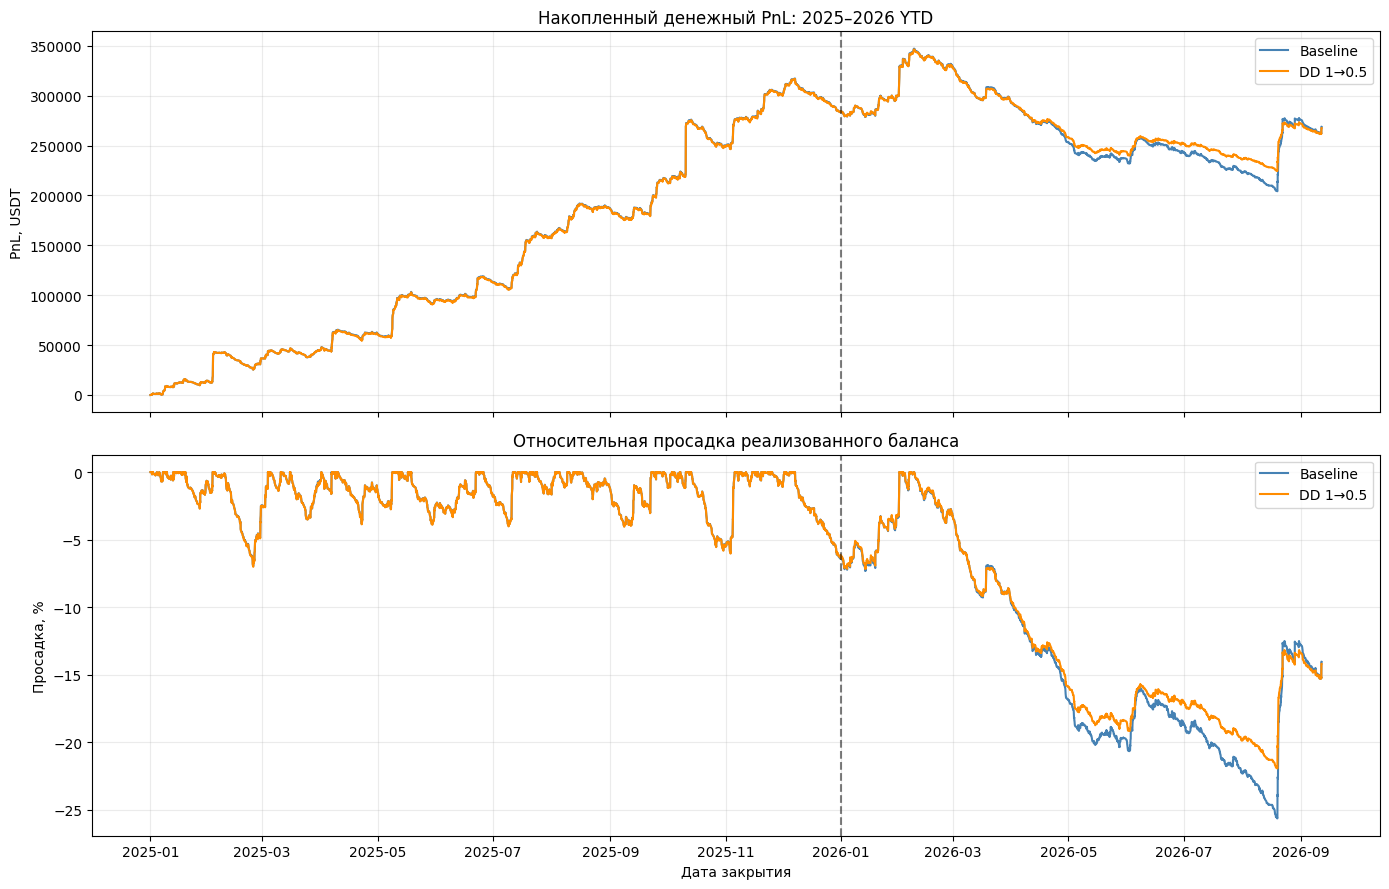

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for method in methods:
    axes[0].plot(evaluation_pnl.index, evaluation_pnl[method], label=method, color=colors[method])
    axes[1].plot(evaluation_drawdown_pct.index, evaluation_drawdown_pct[method], label=method, color=colors[method])
axes[0].set(title='Накопленный денежный PnL: 2025–2026 YTD', ylabel='PnL, USDT')
axes[1].set(title='Относительная просадка реализованного баланса', ylabel='Просадка, %', xlabel='Дата закрытия')
for ax in axes:
    ax.axvline(pd.Timestamp('2026-01-01'), color='black', linestyle='--', alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

In [25]:
strategy_comparison_trades = selective_trades.loc[selective_trades['exit_day'].between(evaluation_start, evaluation_end)].sort_values(['strategy_name', 'exit_date', 'trade_id'], kind='stable').copy()
comparison_days = pd.date_range(evaluation_start, evaluation_end, freq='D')
strategy_cash_totals = strategy_comparison_trades.groupby('strategy_name')[selective_methods].sum()
rolling_window, rolling_min_periods = 250, 100
strategy_metric_methods = methods + ['Selected 1→0']
comparison_rows = []

In [26]:
for strategy_name, strategy_data in strategy_comparison_trades.groupby('strategy_name', sort=True):
    first_day = max(evaluation_start, first_entry.loc[strategy_name])
    for method in strategy_metric_methods:
        event_pnl = strategy_data.groupby('exit_date')[method].sum().sort_index()
        curve = event_pnl.cumsum()
        event_depth = curve.cummax().clip(lower=0) - curve
        daily = event_pnl.resample('D').sum().reindex(comparison_days, fill_value=0.0)
        daily_curve = daily.cumsum()
        depth = (daily_curve.cummax().clip(lower=0) - daily_curve).loc[first_day:]
        contributions = daily / cash_previous_balance.loc[comparison_days, method]
        dar, mdd = depth.quantile(0.95), event_depth.max()
        underwater = depth > 1e-9
        blocks = (~underwater).cumsum()
        std = contributions.std()
        downside = np.sqrt(np.mean(np.minimum(contributions, 0) ** 2))
        trade_depth = strategy_data['exit_date'].map(event_depth).tail(rolling_window)
        rolling_dar = trade_depth.quantile(0.95)
        latest_cdar = trade_depth[trade_depth >= rolling_dar].mean() if len(trade_depth) >= rolling_min_periods else np.nan
        net = strategy_cash_totals.loc[strategy_name, method]
        comparison_rows.append({'strategy_name': strategy_name, 'Method': method, 'net_pnl_usdt': net,
                                'max_drawdown_usdt': mdd, 'DaR_95_usdt': dar, 'CDaR_95_usdt': depth[depth >= dar].mean(),
                                'Sharpe_contribution': contributions.mean() / std * np.sqrt(365) if std > 0 else np.nan,
                                'Sortino_contribution': contributions.mean() / downside * np.sqrt(365) if downside > 0 else np.nan,
                                'RecoveryFactor': net / mdd if mdd > 0 else np.nan,
                                'max_drawdown_duration_days': int(underwater.groupby(blocks).sum().max()),
                                'time_in_drawdown_calendar_pct': underwater.mean() * 100,
                                'annualized_pnl_usdt': net / (len(depth) / 365.25), 'rolling_cdar_250_usdt': latest_cdar})

In [27]:
strategy_comparison = pd.DataFrame(comparison_rows).set_index(['Method', 'strategy_name'])
baseline_strategy_metrics = strategy_comparison.xs('Baseline', level='Method').sort_values('net_pnl_usdt', kind='stable')
controlled_strategy_metrics = strategy_comparison.xs('DD 1→0.5', level='Method').reindex(baseline_strategy_metrics.index)
comparison_metrics = ['net_pnl_usdt', 'max_drawdown_usdt', 'DaR_95_usdt', 'CDaR_95_usdt', 'Sharpe_contribution', 'Sortino_contribution', 'RecoveryFactor', 'max_drawdown_duration_days', 'time_in_drawdown_calendar_pct', 'annualized_pnl_usdt', 'rolling_cdar_250_usdt']
comparison_risk_metrics = ['max_drawdown_usdt', 'DaR_95_usdt', 'CDaR_95_usdt', 'max_drawdown_duration_days', 'time_in_drawdown_calendar_pct', 'rolling_cdar_250_usdt']

comparison_names = {'net_pnl_usdt': 'Итоговый PnL, USDT',
                    'max_drawdown_usdt': 'Макс. просадка вклада, USDT',
                    'DaR_95_usdt': 'DaR 95%, USDT',
                    'CDaR_95_usdt': 'CDaR 95%, USDT',
                    'Sharpe_contribution': 'Sharpe вклада',
                    'Sortino_contribution': 'Sortino вклада',
                    'RecoveryFactor': 'Recovery Factor',
                    'max_drawdown_duration_days': 'Макс. дней в просадке',
                    'time_in_drawdown_calendar_pct': 'Время в просадке, %',
                    'annualized_pnl_usdt': 'PnL на год, USDT',
                    'rolling_cdar_250_usdt': 'Rolling CDaR 250 сделок, USDT'}

comparison_raw = pd.concat({'Baseline': baseline_strategy_metrics[comparison_metrics], 'DD 1→0.5': controlled_strategy_metrics[comparison_metrics]}, names=['Method']).replace([np.inf, -np.inf], np.nan)
comparison_scaled = comparison_raw.rank(pct=True)
comparison_scaled[comparison_risk_metrics] = comparison_raw[comparison_risk_metrics].rank(pct=True, ascending=False)
strategy_metric_changes = controlled_strategy_metrics - baseline_strategy_metrics

In [45]:
# fig, axes = plt.subplots(1, 2, figsize=(31, max(12, len(baseline_strategy_metrics) * 0.35)), sharey=True)
# for ax, (method, title) in zip(axes, [('Baseline', 'Исходные стратегии'), ('DD 1→0.5', 'После управления по просадке')]):
#     values = comparison_raw.xs(method, level='Method').reindex(baseline_strategy_metrics.index).rename(columns=comparison_names)
#     scores = comparison_scaled.xs(method, level='Method').reindex(baseline_strategy_metrics.index).rename(columns=comparison_names)
#     sns.heatmap(scores, ax=ax, annot=values, fmt='.2f', mask=values.isna(), cmap='RdYlGn', vmin=0, vmax=1, linewidths=0.4, annot_kws={'fontsize': 7}, cbar=False)
#     ax.set_title(f'{title}')
#     ax.set_xlabel('Метрика')
#     ax.set_ylabel('Стратегия' if ax is axes[0] else '')
#     plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
#     ax.tick_params(axis='y', labelsize=8)
# axes[1].tick_params(axis='y', left=False, labelleft=False)
# plt.tight_layout()
# plt.show()

### 2.2. Гипотеза 2: ограничение только подозрительных стратегий
Проверяем два варианта для выбранных 24 стратегий: уменьшение новых входов до ×0,5 и их пропуск при том же сигнале DD. Остальные стратегии не меняются. Каждый вариант сравнивается с Baseline. Список выбран по всей истории: оценка отбора ретроспективная, не независимая out-of-sample проверка.

In [29]:
hypothesis2_methods = ['Baseline', 'Selected 1→0.5', 'Selected 1→0']

#### 2.2.1. Сводные денежные результаты: 2025–2026 YTD

In [30]:
selective_summary = cash_evaluation_summary
selective_main_columns = main_columns + ['Trades_half_pct', 'Trades_skipped_pct']
display(selective_summary.loc[hypothesis2_methods, selective_main_columns].round(3))

,Net_PnL_USDT,PnL_retained_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Avg_multiplier,Switches,Trades_half_pct,Trades_skipped_pct
Method,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215,84.976,1.00,0,0.000,0.000
Selected 1→0.5,279892.289,104.077,22.013,18.471,19.673,2.968,2.293,2.578,9.395,215,84.976,0.96,35,8.011,0.000
Selected 1→0,290856.606,108.154,18.335,16.507,17.005,3.708,2.874,2.702,10.037,215,84.976,0.92,35,0.000,8.011


#### 2.2.2. Полугодия 2025 года и 2026 YTD

In [31]:
selective_period_results = all_period_results
selective_2025, selective_stress = year_2025_all, stress_all
display(selective_period_results.loc[pd.IndexSlice[:, hypothesis2_methods], ['Net_PnL_USDT', 'PnL_delta_USDT', 'MDD_pct', 'CDaR95_pct', 'Calmar']].round(3))

Net_PnL_USDT  PnL_delta_USDT  MDD_pct  CDaR95_pct  \
Period   Method                                                              
2025 H1  Baseline          113080.117           0.000    6.967       5.324   
         Selected 1→0.5    112601.225        -478.892    7.014       5.360   
         Selected 1→0      112122.333        -957.784    7.062       5.397   
2025 H2  Baseline          171084.654           0.000    6.431       5.497   
         Selected 1→0.5    171551.919         467.265    6.368       5.487   
         Selected 1→0      172019.185         934.531    6.306       5.478   
2026 YTD Baseline          -15236.798           0.000   25.659      23.954   
         Selected 1→0.5     -4260.855       10975.943   22.013      20.670   
         Selected 1→0        6715.088       21951.886   18.335      17.434   

                         Calmar  
Period   Method                  
2025 H1  Baseline        19.900  
         Selected 1→0.5  19.860  
         Selected 1→0    19.821  
2025 H2  Baseline        20.609  
         Selected 1→0.5  21.051  
         Selected 1→0    21.508  
2026 YTD Baseline        -0.172  
         Selected 1→0.5  -0.056  
         Selected 1→0     0.108

#### 2.2.3. Накопленный PnL и просадки: 2025–2026 YTD

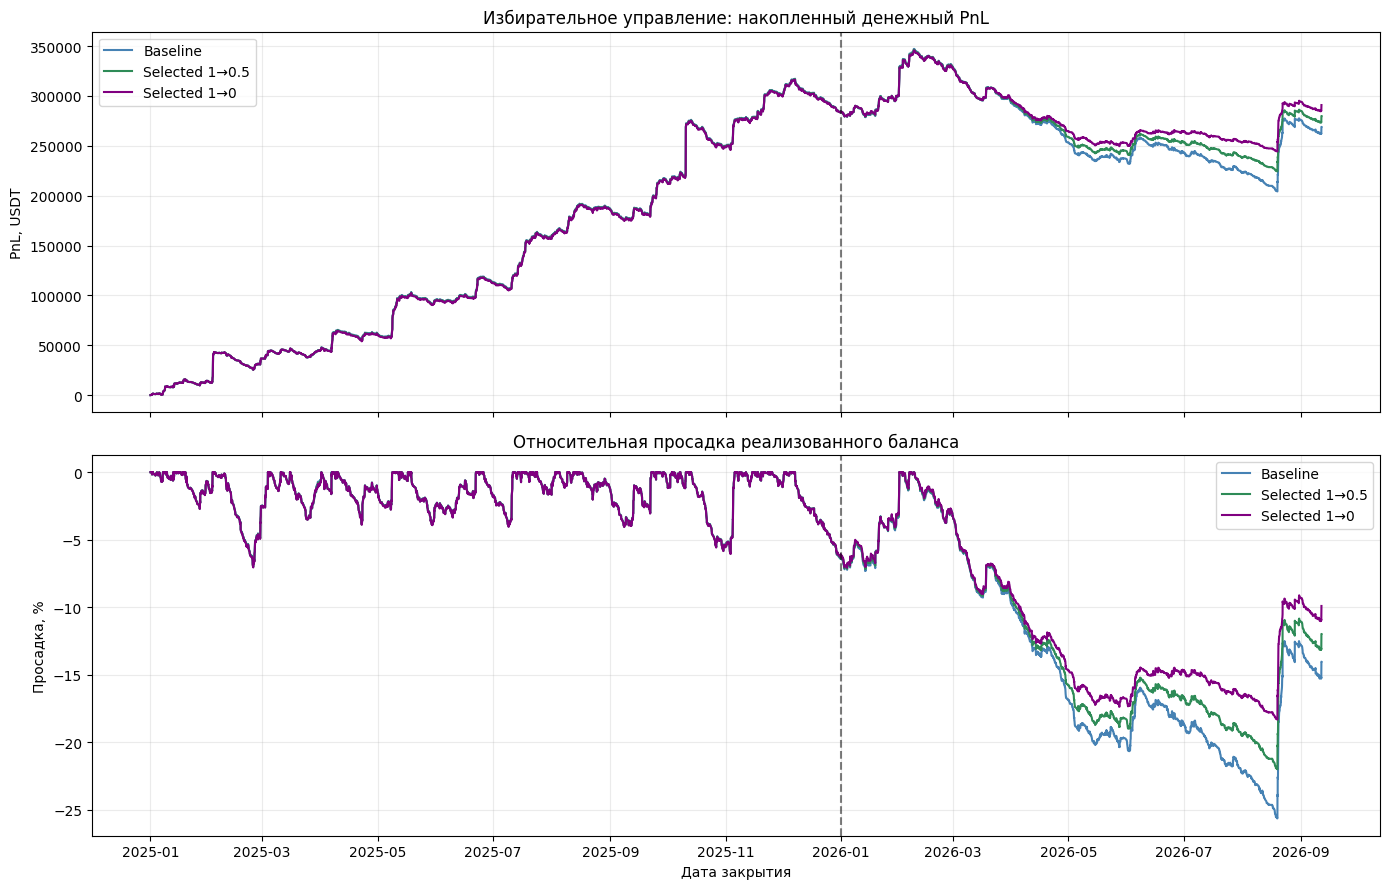

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for method in hypothesis2_methods:
    axes[0].plot(evaluation_pnl.index, evaluation_pnl[method], label=method, color=selective_colors[method])
    axes[1].plot(evaluation_drawdown_pct.index, evaluation_drawdown_pct[method], label=method, color=selective_colors[method])
axes[0].set(title='Избирательное управление: накопленный денежный PnL', ylabel='PnL, USDT')
axes[1].set(title='Относительная просадка реализованного баланса', ylabel='Просадка, %', xlabel='Дата закрытия')
for ax in axes:
    ax.axvline(pd.Timestamp('2026-01-01'), color='black', linestyle='--', alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

### 2.3. Гипотеза 3: индивидуальные пороги для всех стратегий

Порог каждой стратегии рассчитывается по её виртуальной просадке за историю до 2025 года и фиксируется на 2025–2026 YTD. Проверяем MDD, DaR 95% и CDaR 95%, каждый со снижением новых входов до ×0,5 и отключением ×0. Возврат полного размера — при глубине просадки меньше половины порога. До 2025 года новые варианты совпадают с Baseline.

#### 2.3.1. Калибровка индивидуальных порогов

MDD — максимальная глубина; DaR 95% — 95-й процентиль; CDaR 95% — средняя глубина не ниже этого процентиля. Используются дневные наблюдения с первого входа стратегии до 31.12.2024, включая дни без просадки. Меняется способ расчёта порога, а не сам сигнал виртуальной DD.

In [36]:
calibration_end = evaluation_start - pd.Timedelta(days=1)
restore_fraction = 0.5
threshold_types = ['MDD', 'DaR 95%', 'CDaR 95%']
calibration_rows = []
for strategy_name in strategies:
    depth = -virtual_dd.loc[first_entry[strategy_name]:calibration_end, strategy_name]
    dar = depth.quantile(0.95)
    calibration_rows.append({
        'strategy_name': strategy_name,
        'Calibration_days': len(depth),
        'Calibration_closes': int(((trades['strategy_name'] == strategy_name) & (trades['exit_day'] < evaluation_start)).sum()),
        'MDD': depth.max(),
        'DaR 95%': dar,
        'CDaR 95%': depth.loc[depth >= dar].mean()
    })
individual_thresholds = pd.DataFrame(calibration_rows).set_index('strategy_name').reindex(strategies)
threshold_values = individual_thresholds[threshold_types]

#### 2.3.2. Ограничения новых входов и денежные результаты сделок

In [37]:
hypothesis3_multiplier_columns = {'Baseline': multiplier_columns['Baseline']}
hypothesis3_trades = trades.copy()
hypothesis3_modes = {}
hypothesis3_switches = pd.DataFrame({'Baseline': 0}, index=calendar)
hypothesis3_restricted = pd.DataFrame(index=calendar)
hypothesis3_colors = {'Baseline': 'steelblue'}
known_depth_at_entry = (-virtual_dd).shift(1).fillna(0)

for threshold_type in threshold_types:
    threshold = individual_thresholds[threshold_type].to_numpy()
    restricted_state = np.zeros(len(strategies), dtype=bool)
    restriction = pd.DataFrame(False, index=calendar, columns=strategies)
    for day in calendar[calendar >= evaluation_start]:
        known_depth = known_depth_at_entry.loc[day].to_numpy()
        restricted_state = np.where(known_depth >= threshold, True,
                                   np.where(known_depth < restore_fraction * threshold, False, restricted_state))
        restriction.loc[day] = restricted_state
    hypothesis3_modes[threshold_type] = restriction
    switches = restriction.ne(restriction.shift(1).fillna(False)).sum(axis=1)
    hypothesis3_restricted[threshold_type] = (restriction & active).sum(axis=1)
    restricted_at_entry = restriction.to_numpy()[day_positions, strategy_positions]
    for multiplier, color in [(0.5, 'darkorange'), (0.0, 'purple')]:
        method = f'{threshold_type} 1→{multiplier:g}'
        column = f'multiplier_h3_{len(hypothesis3_multiplier_columns)}'
        hypothesis3_colors[method] = color
        hypothesis3_multiplier_columns[method] = column
        hypothesis3_trades[column] = np.where(restricted_at_entry, multiplier, 1.0)
        hypothesis3_switches[method] = switches

hypothesis3_portfolio = build_cash_portfolio(hypothesis3_trades, hypothesis3_multiplier_columns,
                                           hypothesis3_switches, baseline=cash_portfolio)
hypothesis3_methods = hypothesis3_portfolio['methods']
hypothesis3_pnl, hypothesis3_daily = hypothesis3_portfolio['pnl'], hypothesis3_portfolio['daily']
hypothesis3_equity = hypothesis3_portfolio['equity']

/var/folders/bf/l1cb53l51692xrpcg6tzdbmm0000gn/T/ipykernel_9806/433393537.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  switches = restriction.ne(restriction.shift(1).fillna(False)).sum(axis=1)
/var/folders/bf/l1cb53l51692xrpcg6tzdbmm0000gn/T/ipykernel_9806/433393537.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  switches = restriction.ne(restriction.shift(1).fillna(False)).sum(axis=1)
/var/folders/bf/l1cb53l51692xrpcg6tzdbmm0000gn/T/ipykernel_9806/433393537.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is 

#### 2.3.3. Денежные результаты за 2025–2026 YTD

In [38]:
hypothesis3_summary = cash_metrics(evaluation_start, evaluation_end, hypothesis3_portfolio)
hypothesis3_columns = main_columns + ['PnL_delta_USDT', 'Trades_half_pct', 'Trades_skipped_pct']
display(hypothesis3_summary[hypothesis3_columns].round(3))

,Net_PnL_USDT,PnL_retained_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Avg_multiplier,Switches,PnL_delta_USDT,Trades_half_pct,Trades_skipped_pct
Method,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215,84.976,1.000,0,0.000,0.000,0.000
MDD 1→0.5,264544.343,98.370,20.880,17.592,18.975,2.960,2.299,2.554,9.336,215,84.976,0.916,142,-4383.630,16.730,0.000
MDD 1→0,260160.713,96.740,15.998,14.896,15.302,3.808,2.982,2.612,9.808,215,85.137,0.833,142,-8767.260,0.000,16.730
DaR 95% 1→0.5,261277.270,97.155,18.811,15.887,17.026,3.251,2.595,2.577,9.529,215,85.137,0.879,269,-7650.703,24.248,0.000
DaR 95% 1→0,253626.567,94.310,11.507,11.020,11.146,5.179,4.291,2.648,10.103,215,85.784,0.758,269,-15301.406,0.000,24.248
CDaR 95% 1→0.5,267640.228,99.521,19.159,16.262,17.340,3.259,2.560,2.595,9.602,215,84.976,0.899,176,-1287.745,20.177,0.000
CDaR 95% 1→0,266352.484,99.042,12.583,11.897,12.099,4.941,3.962,2.686,10.300,215,85.137,0.798,176,-2575.489,0.000,20.177


#### 2.3.4. Результаты по отдельным периодам

In [39]:
hypothesis3_periods = pd.concat({name: cash_metrics(row.Start, row.End, hypothesis3_portfolio)
                                for name, row in periods.iterrows()}, names=['Period', 'Method'])
display(hypothesis3_periods[['Net_PnL_USDT', 'PnL_delta_USDT', 'MDD_pct', 'CDaR95_pct',
                            'Calmar', 'Max_DD_duration_days', 'Trades_half_pct', 'Trades_skipped_pct']].round(3))

Net_PnL_USDT  PnL_delta_USDT  MDD_pct  CDaR95_pct  \
Period   Method                                                              
2025 H1  Baseline          113080.117           0.000    6.967       5.324   
         MDD 1→0.5         109461.427       -3618.690    6.961       5.326   
         MDD 1→0           105842.737       -7237.380    6.956       5.328   
         DaR 95% 1→0.5     106872.587       -6207.530    6.704       5.216   
         DaR 95% 1→0       100665.057      -12415.060    6.499       5.106   
         CDaR 95% 1→0.5    108889.849       -4190.268    6.872       5.313   
         CDaR 95% 1→0      104699.581       -8380.536    6.776       5.302   
2025 H2  Baseline          171084.654           0.000    6.431       5.497   
         MDD 1→0.5         170654.332        -430.322    6.356       5.497   
         MDD 1→0           170224.010        -860.644    6.280       5.501   
         DaR 95% 1→0.5     163627.378       -7457.276    6.255       5.539   
         DaR 95% 1→0       156170.102      -14914.552    6.520       5.616   
         CDaR 95% 1→0.5    168138.362       -2946.292    6.314       5.509   
         CDaR 95% 1→0      165192.069       -5892.585    6.219       5.529   
2026 YTD Baseline          -15236.798           0.000   25.659      23.954   
         MDD 1→0.5         -15571.416        -334.618   20.880      19.778   
         MDD 1→0           -15906.035        -669.237   15.998      15.527   
         DaR 95% 1→0.5      -9222.695        6014.103   18.811      17.754   
         DaR 95% 1→0        -3208.593       12028.205   11.507      11.245   
         CDaR 95% 1→0.5     -9387.982        5848.816   19.159      18.097   
         CDaR 95% 1→0       -3539.166       11697.632   12.583      12.229   

                         Calmar  Max_DD_duration_days  Trades_half_pct  \
Period   Method                                                          
2025 H1  Baseline        19.900                    33            0.000   
         MDD 1→0.5       19.143                    33            2.935   
         MDD 1→0         18.395                    33            0.000   
         DaR 95% 1→0.5   19.310                    33            8.062   
         DaR 95% 1→0     18.538                    33            0.000   
         CDaR 95% 1→0.5  19.271                    33            5.362   
         CDaR 95% 1→0    18.639                    33            0.000   
2025 H2  Baseline        20.609                    36            0.000   
         MDD 1→0.5       21.072                    36            0.643   
         MDD 1→0         21.556                    36            0.000   
         DaR 95% 1→0.5   20.554                    36            3.949   
         DaR 95% 1→0     19.096                    37            0.000   
         CDaR 95% 1→0.5  20.880                    36            1.430   
         CDaR 95% 1→0    21.086                    36            0.000   
2026 YTD Baseline        -0.172                   215            0.000   
         MDD 1→0.5       -0.217                   215           37.578   
         MDD 1→0         -0.292                   215            0.000   
         DaR 95% 1→0.5   -0.146                   215           49.711   
         DaR 95% 1→0     -0.086                   215            0.000   
         CDaR 95% 1→0.5  -0.144                   215           43.601   
         CDaR 95% 1→0    -0.084                   215            0.000   

                         Trades_skipped_pct  
Period   Method                              
2025 H1  Baseline                     0.000  
         MDD 1→0.5                    0.000  
         MDD 1→0                      2.935  
         DaR 95% 1→0.5                0.000  
         DaR 95% 1→0                  8.062  
         CDaR 95% 1→0.5               0.000  
         CDaR 95% 1→0                 5.362  
2025 H2  Baseline                     0.000  
         MDD 1→0.5                    0.000  
         MDD 1→0     

#### 2.3.5. Денежный PnL и просадка портфеля

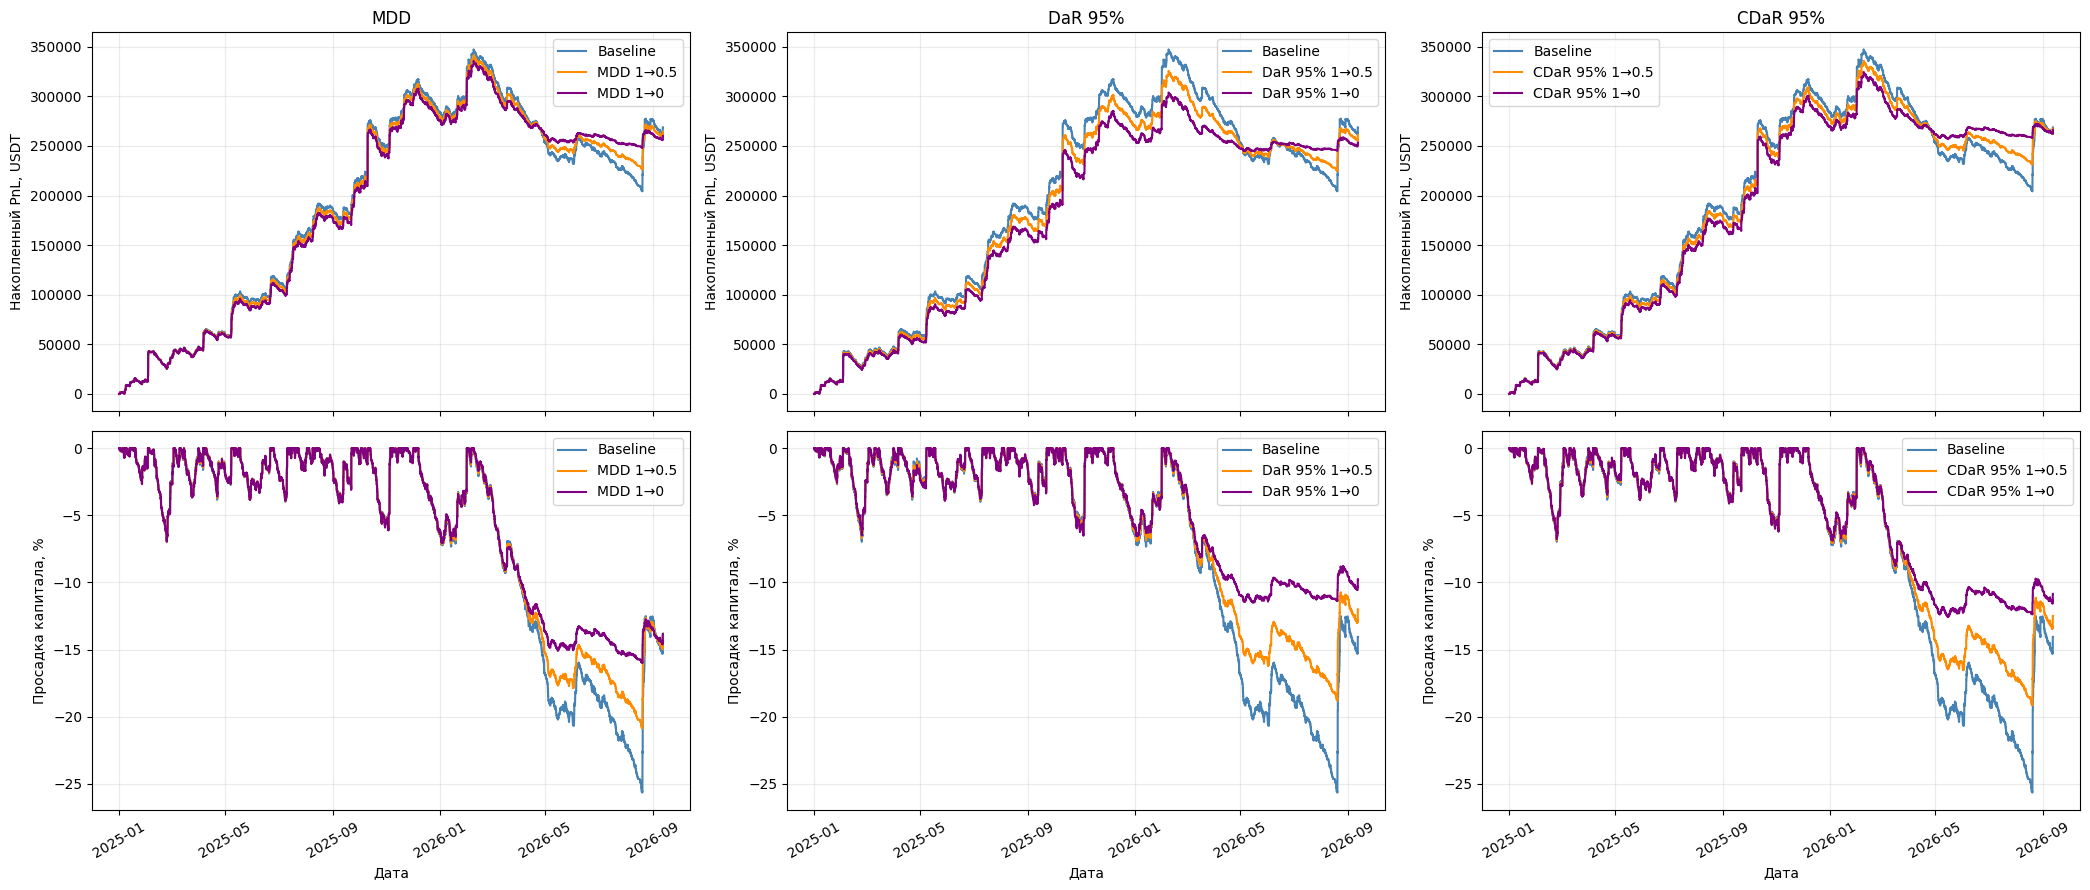

In [40]:
hypothesis3_eval_equity = pd.concat([
    hypothesis3_summary['Start_USDT'].to_frame().T.set_axis([evaluation_start]),
    hypothesis3_equity.loc[(hypothesis3_equity.index >= evaluation_start) &
                          (hypothesis3_equity.index < evaluation_end + pd.Timedelta(days=1))]
])
hypothesis3_eval_pnl = hypothesis3_eval_equity - hypothesis3_summary['Start_USDT']
hypothesis3_eval_dd = (hypothesis3_eval_equity / hypothesis3_eval_equity.cummax() - 1) * 100
fig, axes = plt.subplots(2, 3, figsize=(21, 9), sharex=True)
for col, threshold_type in enumerate(threshold_types):
    group = ['Baseline', f'{threshold_type} 1→0.5', f'{threshold_type} 1→0']
    for method in group:
        axes[0, col].step(hypothesis3_eval_pnl.index, hypothesis3_eval_pnl[method], where='post',
                          label=method, color=hypothesis3_colors[method])
        axes[1, col].step(hypothesis3_eval_dd.index, hypothesis3_eval_dd[method], where='post',
                          label=method, color=hypothesis3_colors[method])
    axes[0, col].set(title=threshold_type, ylabel='Накопленный PnL, USDT')
    axes[1, col].set(ylabel='Просадка капитала, %', xlabel='Дата')
    for ax in axes[:, col]:
        ax.legend()
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

На проверяемой истории все шесть вариантов снизили денежную MDD, но уменьшили итоговый PnL. Пороги DaR 95% дали наименьшую просадку, CDaR 95% — меньшую потерю прибыли. При одинаковом размере ограничения CDaR 95% оказался лучше MDD одновременно по PnL, MDD и Calmar.

### 2.4. Гипотеза 4: индивидуальный порог и отключение без возврата

Для всех 93 стратегий используем те же пороги MDD, DaR 95% и CDaR 95%, рассчитанные до 2025 года. После первого достижения порога в 2025–2026 YTD новые входы отключаются до конца периода, даже если виртуальная просадка восстановилась.

#### 2.4.1. Новые правила отключения

In [41]:
hypothesis4_trades = trades.copy()
hypothesis4_multiplier_columns = {'Baseline': multiplier_columns['Baseline']}
hypothesis4_modes = {}
hypothesis4_switches = pd.DataFrame({'Baseline': 0}, index=calendar)
hypothesis4_permanent_methods = {}
for threshold_type in threshold_types:
    reached = known_depth_at_entry.loc[evaluation_start:].ge(individual_thresholds[threshold_type], axis='columns')
    disabled = reached.cummax().reindex(calendar, fill_value=False)
    hypothesis4_modes[threshold_type] = disabled
    method = f'{threshold_type} 1→0 без возврата'
    column = f'multiplier_h4_{len(hypothesis4_multiplier_columns)}'
    hypothesis4_permanent_methods[threshold_type] = method
    hypothesis4_multiplier_columns[method] = column
    hypothesis4_trades[column] = np.where(disabled.to_numpy()[day_positions, strategy_positions], 0.0, 1.0)
    hypothesis4_switches[method] = disabled.ne(disabled.shift(1).fillna(False)).sum(axis=1)

hypothesis4_portfolio = build_cash_portfolio(hypothesis4_trades, hypothesis4_multiplier_columns,
                                           hypothesis4_switches, baseline=cash_portfolio)
hypothesis4_pnl = hypothesis4_portfolio['pnl']

/var/folders/bf/l1cb53l51692xrpcg6tzdbmm0000gn/T/ipykernel_9806/658376233.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hypothesis4_switches[method] = disabled.ne(disabled.shift(1).fillna(False)).sum(axis=1)
/var/folders/bf/l1cb53l51692xrpcg6tzdbmm0000gn/T/ipykernel_9806/658376233.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hypothesis4_switches[method] = disabled.ne(disabled.shift(1).fillna(False)).sum(axis=1)
/var/folders/bf/l1cb53l51692xrpcg6tzdbmm0000gn/T/ipykernel_9806/658376233.py:15: FutureWarning: Downcasting object dtype arrays on

#### 2.4.2. Денежные результаты за 2025–2026 YTD

In [42]:
hypothesis4_summary = cash_metrics(evaluation_start, evaluation_end, hypothesis4_portfolio)
# display(hypothesis4_summary)
hypothesis4_comparison = pd.concat([hypothesis3_summary.loc[['Baseline']]] + [
    pd.concat([hypothesis3_summary.loc[[f'{threshold_type} 1→0']],
               hypothesis4_summary.loc[[hypothesis4_permanent_methods[threshold_type]]]])
    for threshold_type in threshold_types
])
hypothesis4_columns = main_columns + ['PnL_delta_USDT', 'Trades_skipped_pct']
display(hypothesis4_comparison[hypothesis4_columns].round(3))

,Net_PnL_USDT,PnL_retained_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Avg_multiplier,Switches,PnL_delta_USDT,Trades_skipped_pct
Method,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215,84.976,1.000,0,0.000,0.000
MDD 1→0,260160.713,96.740,15.998,14.896,15.302,3.808,2.982,2.612,9.808,215,85.137,0.833,142,-8767.260,16.730
MDD 1→0 без возврата,247626.733,92.079,13.333,12.756,12.924,4.379,3.578,2.678,10.430,215,84.653,0.718,63,-21301.240,28.241
DaR 95% 1→0,253626.567,94.310,11.507,11.020,11.146,5.179,4.291,2.648,10.103,215,85.784,0.758,269,-15301.406,24.248
DaR 95% 1→0 без возврата,191451.315,71.191,7.931,7.372,7.565,5.876,5.627,2.774,10.996,221,86.914,0.490,78,-77476.658,51.032
CDaR 95% 1→0,266352.484,99.042,12.583,11.897,12.099,4.941,3.962,2.686,10.300,215,85.137,0.798,176,-2575.489,20.177
CDaR 95% 1→0 без возврата,225219.210,83.747,10.513,9.713,9.930,5.113,4.484,2.740,10.617,215,84.814,0.624,69,-43708.763,37.609


#### 2.4.3. Денежный PnL и просадка портфеля

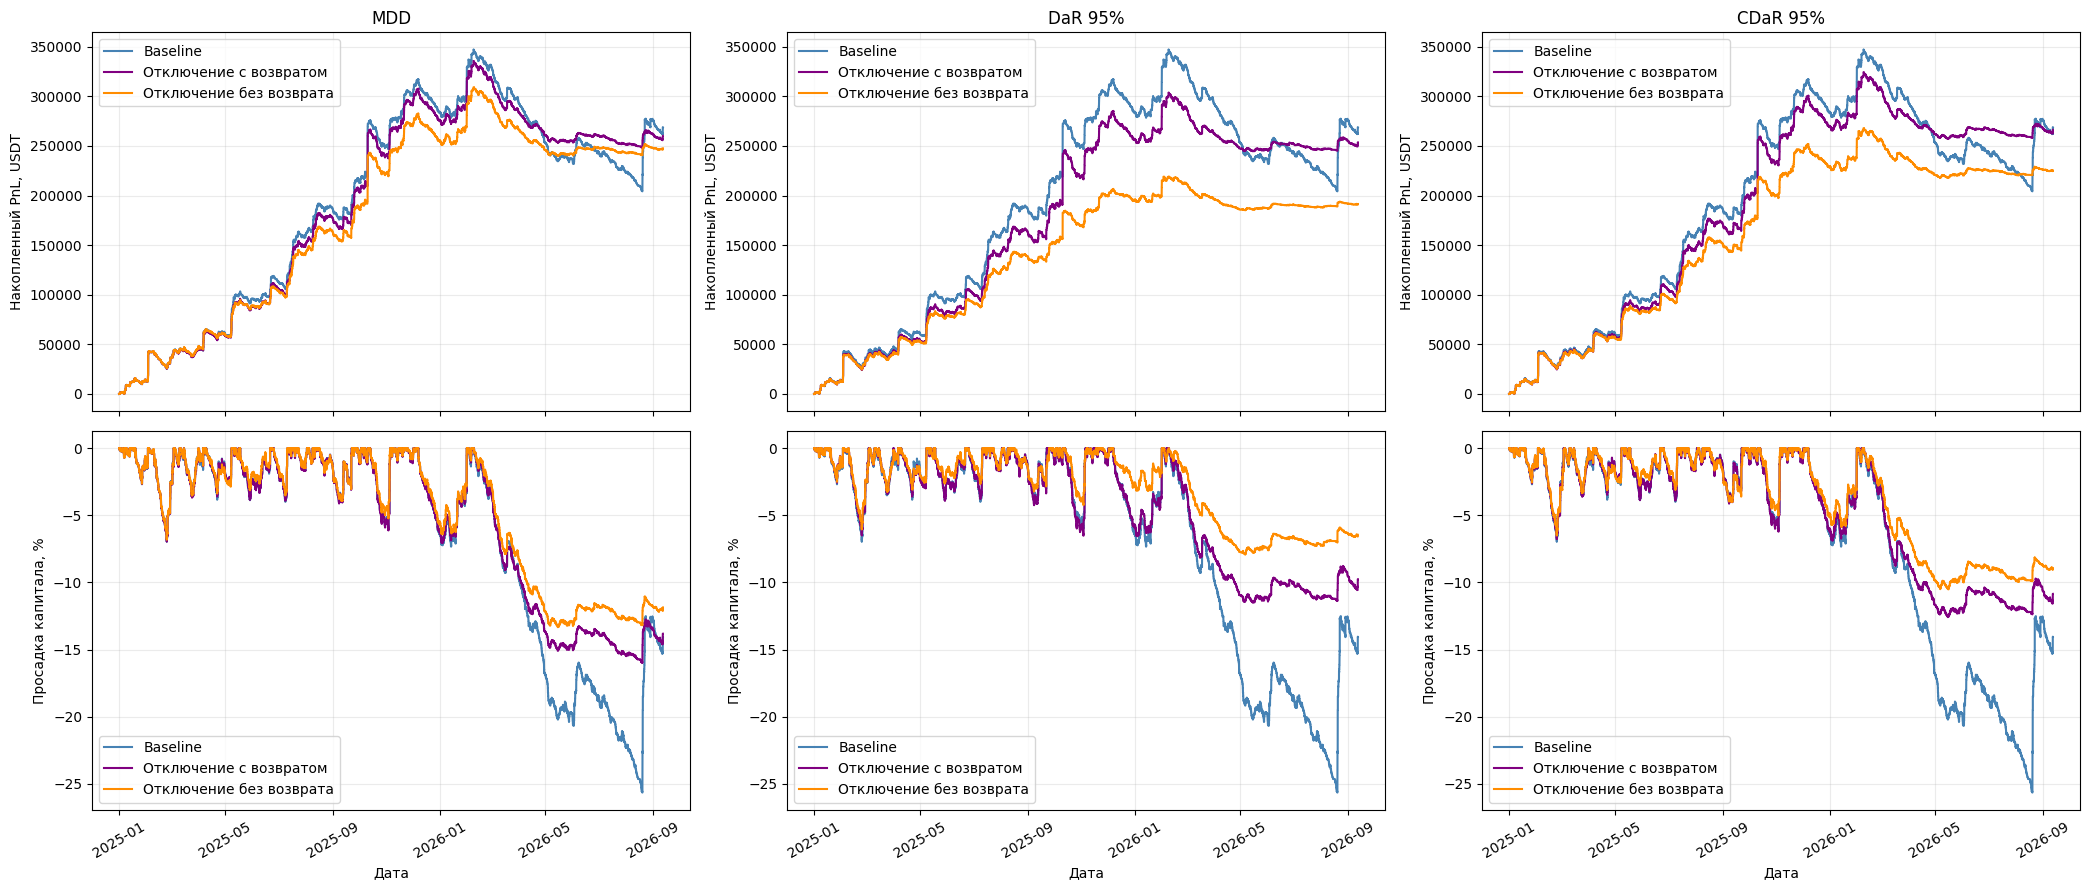

In [43]:
hypothesis4_eval_equity = pd.concat([
    hypothesis4_summary['Start_USDT'].to_frame().T.set_axis([evaluation_start]),
    hypothesis4_portfolio['equity'].loc[(hypothesis4_portfolio['equity'].index >= evaluation_start) &
                                       (hypothesis4_portfolio['equity'].index < evaluation_end + pd.Timedelta(days=1))]
])
hypothesis4_eval_pnl = hypothesis4_eval_equity - hypothesis4_summary['Start_USDT']
hypothesis4_eval_dd = (hypothesis4_eval_equity / hypothesis4_eval_equity.cummax() - 1) * 100
fig, axes = plt.subplots(2, 3, figsize=(21, 9), sharex=True)
for col, threshold_type in enumerate(threshold_types):
    temporary = f'{threshold_type} 1→0'
    permanent = hypothesis4_permanent_methods[threshold_type]
    for pnl, dd, method, label, color in [
        (hypothesis3_eval_pnl, hypothesis3_eval_dd, 'Baseline', 'Baseline', 'steelblue'),
        (hypothesis3_eval_pnl, hypothesis3_eval_dd, temporary, 'Отключение с возвратом', 'purple'),
        (hypothesis4_eval_pnl, hypothesis4_eval_dd, permanent, 'Отключение без возврата', 'darkorange')
    ]:
        axes[0, col].step(pnl.index, pnl[method], where='post', label=label, color=color)
        axes[1, col].step(dd.index, dd[method], where='post', label=label, color=color)
    axes[0, col].set(title=threshold_type, ylabel='Накопленный PnL, USDT')
    axes[1, col].set(ylabel='Просадка капитала, %', xlabel='Дата')
    for ax in axes[:, col]:
        ax.legend()
    axes[1, col].xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    axes[1, col].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    axes[1, col].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

Отключение без возврата дополнительно снизило просадку для всех трёх порогов, но уменьшило прибыль относительно временного отключения. Повторные включения на этой истории в совокупности приносили положительный денежный результат. DaR 95% дал минимальную MDD и наибольшую потерю прибыли; MDD — меньшую потерю прибыли среди вариантов без возврата. Максимальная длительность просадки не сократилась.